# Compare all three models with 29 shared features

Compare the updated boosted-tree run against the transformer and Random Forest on **six quarterly development folds: 2024 Q1–2025 Q2**. This notebook reads saved fold metrics and checks their agreement with `notebooks/results/summary.csv`; it does not retrain models or load the final holdout.

All three summary rows now report **29 logical features**. The recorded onset counts must match in every quarter. Transformer and Random Forest training counts can also be checked; the boosted-tree CSV does not record training counts or a feature-name manifest, so exact prediction-row and source-version equality cannot be established from these files alone. The existing shared module still matches the Random Forest manifest.

Primary score: **AP onsets**, a row-level ranking metric on currently uncongested, measured stations with known outcomes. Operational warning metrics use the common **0.5 cutoff**, not matched false-alarm budgets. The transformer uses historical sequences; the tree models use tabular feature vectors.

Source provenance: the updated scores are in `boosted_trees_folds.csv`. A shared-29 boosted-tree recipe is present in `feature-selection-individual-features-modified-earlier.ipynb`. The dedicated `boosted_trees_model.ipynb` currently contains an unexecuted logistic template, so it is not treated as an independently verified training recipe for this comparison.

In [1]:
# Resolve repository paths from the root or any notebook subfolder.
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks" / "safeflow_features.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch this notebook from inside the SafeFlow repository")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks"))

from pathlib import Path
from datetime import datetime
import hashlib
import itertools
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks" / "results" / "summary.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Start this notebook within the SafeFlow project")
SOURCES = ROOT / "notebooks" / "results"
OUT = SOURCES / "model_comparison_29_features" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUT.mkdir(parents=True, exist_ok=False)
MODELS = {"Boosted trees": "boosted_trees", "Transformer": "transformer_shared_plus_agreed_features",
          "Random Forest": "random_forest_shared_29_features"}
COLORS = {"Boosted trees": "#14857c", "Transformer": "#d98522", "Random Forest": "#4776a8"}
EXPECTED_FOLDS = ["2024-01 to 2024-03", "2024-04 to 2024-06", "2024-07 to 2024-09",
                  "2024-10 to 2024-12", "2025-01 to 2025-03", "2025-04 to 2025-06"]
summary = pd.read_csv(SOURCES / "summary.csv")
if summary.model.duplicated().any():
    raise ValueError("Duplicate model rows in team summary")
summary = summary.set_index("model").loc[list(MODELS.values())].copy()
assert summary.features.eq(29).all(), "Only the 29-feature runs should enter this comparison"
folds, source_hashes = {}, {}
source_hashes["summary.csv"] = hashlib.sha256((SOURCES / "summary.csv").read_bytes()).hexdigest()
for label, model in MODELS.items():
    file = SOURCES / f"{model}_folds.csv"
    table = pd.read_csv(file).set_index("fold")
    assert table.index.is_unique and set(table.index) == set(EXPECTED_FOLDS), f"Incomplete fold coverage: {model}"
    table = table.loc[EXPECTED_FOLDS]
    assert np.isfinite(table.select_dtypes(include="number").to_numpy()).all()
    assert table["AP, onsets"].between(0, 1).all() and table.Brier.between(0, 1).all()
    assert table["caught ≥15 min"].between(0, 1).all()
    folds[label] = table
    source_hashes[file.name] = hashlib.sha256(file.read_bytes()).hexdigest()
onsets = pd.concat({label: table.onsets for label, table in folds.items()}, axis=1)
assert onsets.nunique(axis=1).eq(1).all(), "Onset populations differ between model runs"
assert folds["Transformer"].train_rows.eq(folds["Random Forest"].train_rows).all()
checks = []
for label, model in MODELS.items():
    table, row = folds[label], summary.loc[model]
    metrics = {"AP onsets (mean)": table["AP, onsets"].mean(), "AP onsets (std)": table["AP, onsets"].std(),
               "AP onsets (worst fold)": table["AP, onsets"].min(), "Brier": table.Brier.mean(),
               "caught ≥15 min @0.5": table["caught ≥15 min"].mean(),
               "false alarms/day @0.5": table["false alarms / day"].mean(),
               "wrong-alert hours/day @0.5": table["wrong-alert hours / day"].mean()}
    for metric, value in metrics.items():
        assert np.isclose(value, float(row[metric]), atol=1e-4, rtol=0), (label, metric, value, row[metric])
        checks.append(dict(model=label, metric=metric, from_fold_csv=value, from_summary=float(row[metric])))
shared_hash = hashlib.sha256((ROOT / "notebooks" / "safeflow_features.py").read_bytes()).hexdigest()
rf_manifest = json.loads((SOURCES / "random_forest_shared_29_features_manifest.json").read_text(encoding="utf-8"))
assert rf_manifest["shared_code_sha256"] == shared_hash
summary["label"] = list(MODELS)
summary = summary.set_index("label")
print("PASS: all three declare 29 features; six matching quarters; identical onset counts; summary agrees with fold CSVs")
print("PASS: transformer/RF training counts match; current shared module matches the RF manifest")
print("Source CSV rounding tolerance: 0.0001. Output:", OUT)
display(summary.round(4))

PASS: all three declare 29 features; six matching quarters; identical onset counts; summary agrees with fold CSVs
PASS: transformer/RF training counts match; current shared module matches the RF manifest
Source CSV rounding tolerance: 0.0001. Output: C:\Erdos\Project\safeflow\notebooks\results\model_comparison_29_features\20261102_230041_937007


,date run,features,AP onsets (mean),AP onsets (std),AP onsets (worst fold),Brier,caught ≥15 min @0.5,false alarms/day @0.5,wrong-alert hours/day @0.5
label,,,,,,,,,
Boosted trees,2026-11-02,29,0.7663,0.0108,0.7550,0.0220,0.6410,31.1239,5.0379
Transformer,2026-10-31,29,0.7625,0.0168,0.7317,0.0223,0.6633,30.4317,5.5437
Random Forest,2026-10-31,29,0.7495,0.0088,0.7384,0.0230,0.5258,30.0483,4.4619


## 1. Mean ranking, quarterly consistency, and worst-quarter performance

Higher AP is better. Mean AP averages the six quarterly scores equally, rather than pooling all predictions. Error bars show **standard deviation across quarters**, not a confidence interval or a significance test. The full-range bar chart shows absolute values; the quarterly line chart deliberately zooms its AP axis so the differences can be inspected.

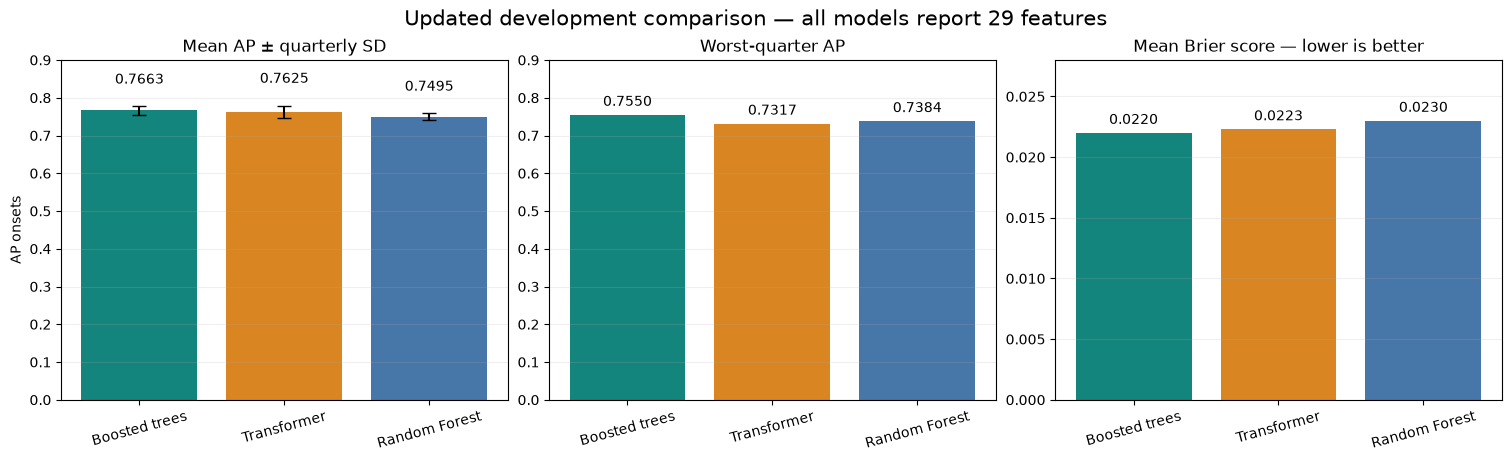

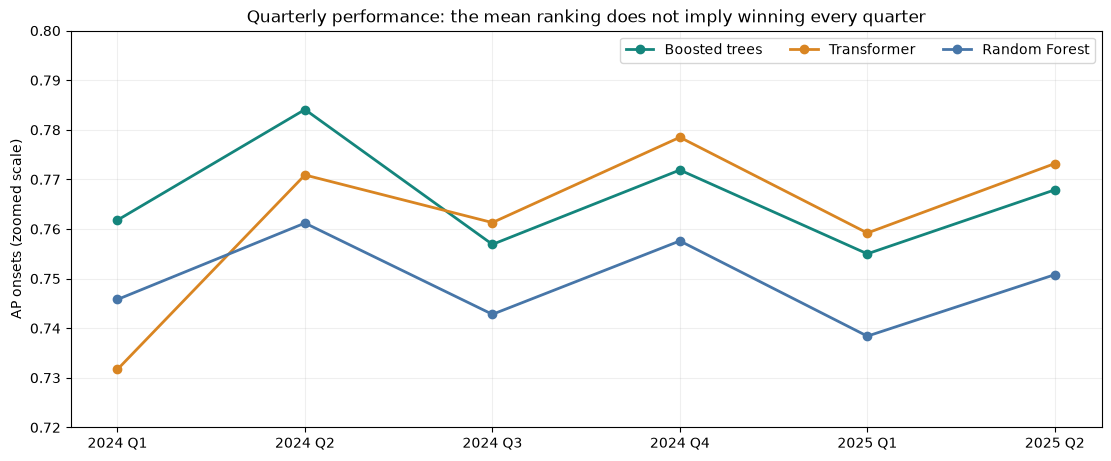

,Boosted trees,Transformer,Random Forest
fold,,,
2024-01 to 2024-03,0.7618,0.7317,0.7458
2024-04 to 2024-06,0.7841,0.7709,0.7612
2024-07 to 2024-09,0.7569,0.7613,0.7428
2024-10 to 2024-12,0.7719,0.7785,0.7576
2025-01 to 2025-03,0.7550,0.7592,0.7384
2025-04 to 2025-06,0.7679,0.7732,0.7508


In [2]:
ap = pd.DataFrame({label: table["AP, onsets"] for label, table in folds.items()})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
labels = list(MODELS)
bars = axes[0].bar(labels, summary["AP onsets (mean)"], yerr=summary["AP onsets (std)"],
                   capsize=5, color=[COLORS[label] for label in labels])
axes[0].bar_label(bars, labels=[f"{v:.4f}" for v in summary["AP onsets (mean)"]], padding=14)
axes[0].set(title="Mean AP ± quarterly SD", ylabel="AP onsets", ylim=(0, 0.9))
bars = axes[1].bar(labels, summary["AP onsets (worst fold)"], color=[COLORS[label] for label in labels])
axes[1].bar_label(bars, labels=[f"{v:.4f}" for v in summary["AP onsets (worst fold)"]], padding=4)
axes[1].set(title="Worst-quarter AP", ylim=(0, 0.9))
bars = axes[2].bar(labels, summary["Brier"], color=[COLORS[label] for label in labels])
axes[2].bar_label(bars, labels=[f"{v:.4f}" for v in summary.Brier], padding=4)
axes[2].set(title="Mean Brier score — lower is better", ylim=(0, 0.028))
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Updated development comparison — all models report 29 features", fontsize=15)
fig.savefig(OUT / "model_summary.png", dpi=180, bbox_inches="tight")
fig.savefig(OUT / "model_summary.svg", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
x = np.arange(6)
for label in labels:
    ax.plot(x, ap[label], marker="o", linewidth=2, color=COLORS[label], label=label)
ax.set(xticks=x, xticklabels=["2024 Q1", "2024 Q2", "2024 Q3", "2024 Q4", "2025 Q1", "2025 Q2"],
       ylabel="AP onsets (zoomed scale)", title="Quarterly performance: the mean ranking does not imply winning every quarter",
       ylim=(0.72, 0.80))
ax.legend(ncol=3, loc="upper right")
ax.grid(alpha=0.2)
fig.savefig(OUT / "quarterly_average_precision.png", dpi=180, bbox_inches="tight")
fig.savefig(OUT / "quarterly_average_precision.svg", bbox_inches="tight")
plt.show()
display(ap.round(4))

**Measured interpretation.** Updated boosted trees have the highest mean AP (**0.7663**), the strongest worst-quarter AP (**0.7550**), and the lowest Brier score (**0.0220**). Transformer mean AP is **0.7625**, while Random Forest is **0.7495**. Random Forest has the smallest quarterly AP standard deviation (**0.0088**, versus boosted trees **0.0108** and transformer **0.0168**), but remains below boosted trees in every quarter.

The transformer leads boosted trees in the last four quarters. Boosted trees lead in the first two, with larger margins—especially 2024 Q1—so they still have the better six-quarter mean. Mean ranking, consistency, and frequency of winning are different summaries. Lower Brier indicates better overall probability error, not proof that calibration alone improved.

## 2. Paired differences on the same quarters

Compare each quarter directly rather than treating the two six-quarter distributions as independent samples. Positive AP differences favor the first model. Win counts and paired mean differences are descriptive: six folds with overlapping training periods are not six independent random experiments, and they do not establish statistical significance or final-holdout superiority.

,first,second,mean_AP_difference,wins,losses,ties,min_AP_difference,max_AP_difference
0,Boosted trees,Transformer,0.0038,2,4,0,-0.0066,0.0301
1,Boosted trees,Random Forest,0.0168,6,0,0,0.0141,0.0229
2,Transformer,Random Forest,0.0130,5,1,0,-0.0141,0.0224


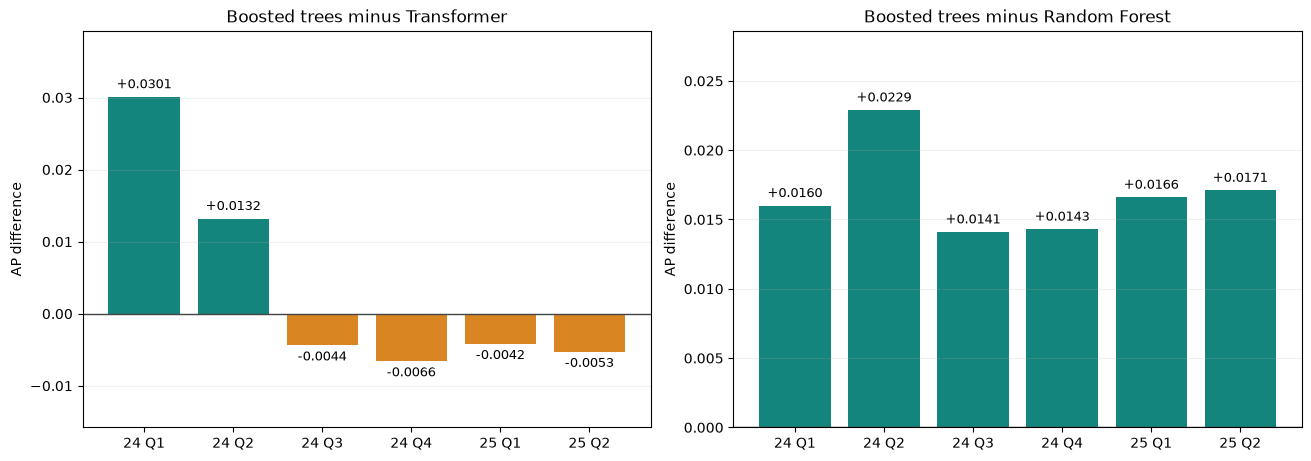

In [3]:
pair_rows, difference_parts = [], []
for first, second in itertools.combinations(labels, 2):
    delta = ap[first] - ap[second]
    pair_rows.append(dict(first=first, second=second, mean_AP_difference=delta.mean(),
                          wins=int((delta > 0).sum()), losses=int((delta < 0).sum()), ties=int((delta == 0).sum()),
                          min_AP_difference=delta.min(), max_AP_difference=delta.max()))
    difference_parts.append(pd.DataFrame({"fold": delta.index, "first": first, "second": second, "AP_difference": delta.to_numpy()}))
paired_summary = pd.DataFrame(pair_rows)
paired_differences = pd.concat(difference_parts, ignore_index=True)
display(paired_summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, second in zip(axes, ["Transformer", "Random Forest"]):
    delta = ap["Boosted trees"] - ap[second]
    bars = ax.bar(np.arange(6), delta, color=["#14857c" if value >= 0 else COLORS[second] for value in delta])
    ax.bar_label(bars, labels=[f"{value:+.4f}" for value in delta], padding=4, fontsize=9)
    ax.axhline(0, color="#444444", linewidth=1)
    ax.set(xticks=np.arange(6), xticklabels=["24 Q1", "24 Q2", "24 Q3", "24 Q4", "25 Q1", "25 Q2"],
           ylabel="AP difference", title=f"Boosted trees minus {second}")
    ax.margins(y=0.25)
    ax.grid(axis="y", alpha=0.2)
fig.savefig(OUT / "paired_boosted_tree_differences.png", dpi=180, bbox_inches="tight")
fig.savefig(OUT / "paired_boosted_tree_differences.svg", bbox_inches="tight")
plt.show()

**Measured interpretation.** Boosted trees exceed Random Forest AP in **6/6 quarters**, with a mean paired gain of about **0.0168**. They exceed transformer AP in **2/6 quarters**, with a mean gain of **0.0038**. The first-quarter boosted-tree advantage is **0.0301**; transformer advantages in the final four quarters are only about **0.0042–0.0066** each. Calling boosted trees the mean-AP leader is supported; calling them the most frequent winner over the transformer is not.

## 3. Early warning versus false-warning burden at threshold 0.5

Each point below is one model at its recorded **0.5 threshold**, using means across the six quarters. The two panels use different costs: episode counts and total wrong-alert duration. They are not threshold-sweep curves and are not comparisons at matched warning budgets. Points farther toward the upper-left offer more early detections for less of the displayed warning cost.

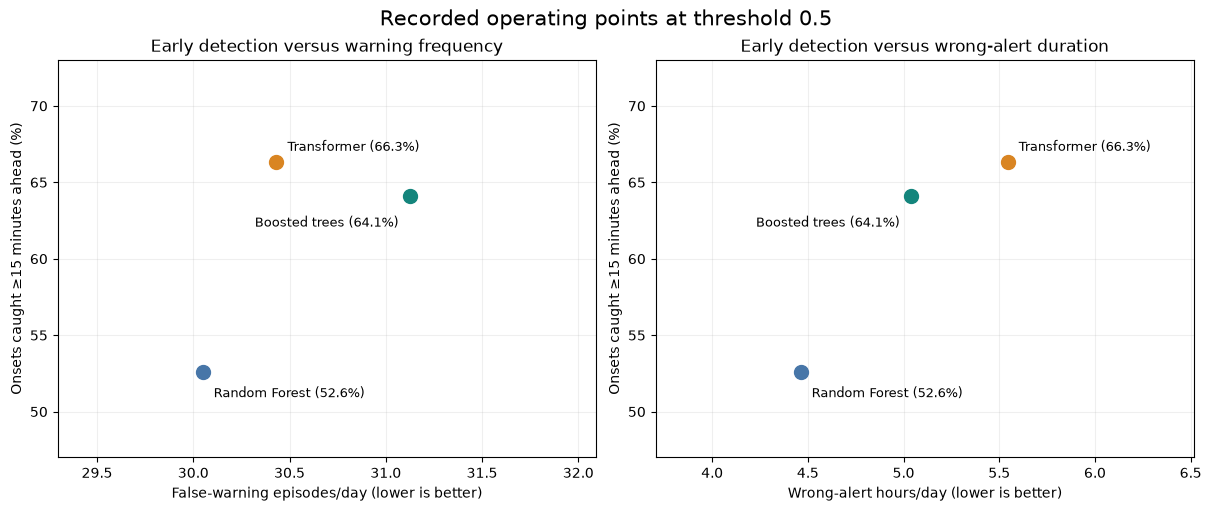

,caught_percent,false_episodes_per_day,wrong_alert_hours_per_day
Boosted trees,64.10,31.124,5.038
Transformer,66.33,30.432,5.544
Random Forest,52.58,30.048,4.462


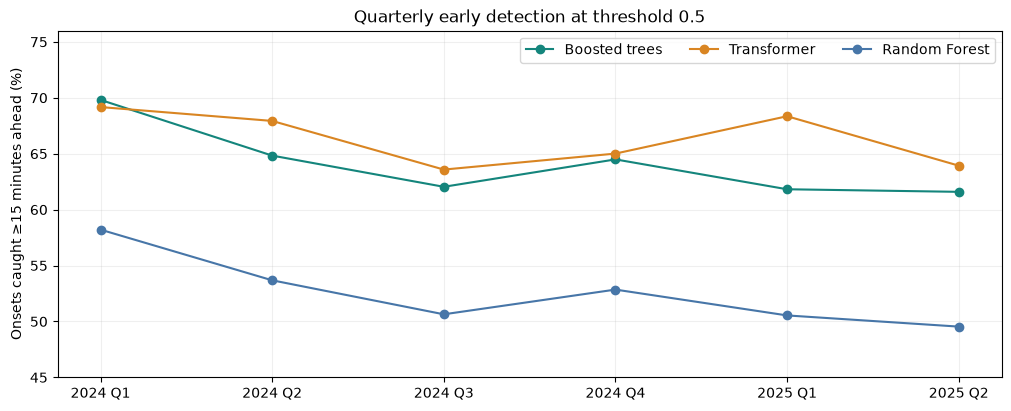

In [4]:
operational = pd.DataFrame(index=labels)
operational["caught_percent"] = 100 * summary["caught ≥15 min @0.5"]
operational["false_episodes_per_day"] = summary["false alarms/day @0.5"]
operational["wrong_alert_hours_per_day"] = summary["wrong-alert hours/day @0.5"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
offsets = {"Boosted trees": (-8, -22), "Transformer": (8, 8), "Random Forest": (8, -18)}
for ax, column, xlabel in zip(axes, ["false_episodes_per_day", "wrong_alert_hours_per_day"],
                              ["False-warning episodes/day (lower is better)", "Wrong-alert hours/day (lower is better)"]):
    for label in labels:
        row = operational.loc[label]
        ax.scatter(row[column], row.caught_percent, s=100, color=COLORS[label], label=label, zorder=3)
        ax.annotate(f"{label} ({row.caught_percent:.1f}%)", (row[column], row.caught_percent),
                    xytext=offsets[label], textcoords="offset points", fontsize=9,
                    ha="right" if label == "Boosted trees" else "left")
    lo, hi = operational[column].min(), operational[column].max()
    ax.set(xlim=(lo - 0.7*(hi-lo), hi + 0.9*(hi-lo)), ylim=(47, 73), xlabel=xlabel,
           ylabel="Onsets caught ≥15 minutes ahead (%)")
    ax.grid(alpha=0.2)
axes[0].set_title("Early detection versus warning frequency")
axes[1].set_title("Early detection versus wrong-alert duration")
fig.suptitle("Recorded operating points at threshold 0.5", fontsize=15)
fig.savefig(OUT / "warning_operating_points.png", dpi=180, bbox_inches="tight")
fig.savefig(OUT / "warning_operating_points.svg", bbox_inches="tight")
plt.show()
display(operational.round(3))

# Quarterly early-detection rates expose variability hidden by the averages.
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for label, table in folds.items():
    ax.plot(np.arange(6), 100*table["caught ≥15 min"], marker="o", color=COLORS[label], label=label)
ax.set(xticks=np.arange(6), xticklabels=["2024 Q1", "2024 Q2", "2024 Q3", "2024 Q4", "2025 Q1", "2025 Q2"],
       ylabel="Onsets caught ≥15 minutes ahead (%)", title="Quarterly early detection at threshold 0.5", ylim=(45, 76))
ax.legend(ncol=3)
ax.grid(alpha=0.2)
fig.savefig(OUT / "quarterly_early_detection.png", dpi=180, bbox_inches="tight")
plt.show()

**Measured operational tradeoff.** Transformer catches **66.33%** of onsets ≥15 minutes early, boosted trees **64.10%**, and Random Forest **52.58%**. Transformer has fewer false-warning episodes than boosted trees (**30.43 vs 31.12/day**), but more total wrong-alert duration (**5.54 vs 5.04 hours/day**). Random Forest has the lowest frequency and duration (**30.05 episodes/day; 4.46 hours/day**), while catching fewer onsets.

Thus boosted trees are the mean-ranking and worst-quarter leader; transformer still leads early detection at this cutoff. Neither dominates the other on every operational cost. The extra detected fraction and the warning-duration difference must be evaluated against an explicit operational budget.

## 4. What this comparison can and cannot establish

- The updated 29-feature boosted-tree model is competitive with the transformer and improves consistently over Random Forest in AP.
- The 0.0038 mean AP advantage over transformer is small and uneven across time; no significance claim is made from these six development folds.
- Equal feature counts and identical recorded onset counts improve comparability, but do not prove exact feature-name, preprocessing, or scored-row equality. Boosted-tree training counts and a feature manifest are absent from the supplied CSV artifacts.
- Boosted-tree and transformer per-row prediction files were not available locally. The notebook therefore does not fabricate PR curves, matched-budget threshold sweeps, calibration curves, or row/day bootstrap uncertainty for those models.
- Before final selection, obtain both models' held-out **development-fold** probabilities and compare the best ≥15-minute detection rates under common episode-count and wrong-alert-duration budgets. Freeze the model and threshold before a separate final holdout check.

No team summary or existing model results are changed. This analysis snapshots the updated source CSVs and saves new comparison files only.

In [5]:
summary.to_csv(OUT / "summary_snapshot.csv")
pd.concat(folds, names=["model", "fold"]).to_csv(OUT / "aligned_fold_metrics.csv")
ap.to_csv(OUT / "quarterly_average_precision.csv")
paired_summary.to_csv(OUT / "paired_AP_summary.csv", index=False)
paired_differences.to_csv(OUT / "paired_AP_differences.csv", index=False)
operational.to_csv(OUT / "operating_points_at_0.5.csv")
pd.DataFrame(checks).to_csv(OUT / "summary_consistency_checks.csv", index=False)
onsets.to_csv(OUT / "onset_count_checks.csv")
validation = dict(models=MODELS, features_reported=29, folds=EXPECTED_FOLDS,
                  source_sha256=source_hashes, shared_module_sha256=shared_hash,
                  summary_rounding_tolerance=1e-4, onset_counts_match=True,
                  transformer_RF_training_counts_match=True, raw_predictions_available={
                      "Boosted trees": False, "Transformer": False, "Random Forest": True},
                  comparison="saved development-fold metrics; no independent retraining or holdout scoring",
                  warning_threshold=0.5)
(OUT / "comparison_manifest.json").write_text(json.dumps(validation, indent=2), encoding="utf-8")
print("Saved comparison notebook outputs and figures:", OUT)
print("Mean AP gain, boosted versus transformer:", (ap["Boosted trees"] - ap.Transformer).mean())
print("Boosted AP wins versus transformer:", int((ap["Boosted trees"] > ap.Transformer).sum()), "of 6")
print("Boosted AP wins versus forest:", int((ap["Boosted trees"] > ap["Random Forest"]).sum()), "of 6")

Saved comparison notebook outputs and figures: C:\Erdos\Project\safeflow\notebooks\results\model_comparison_29_features\20261102_230041_937007
Mean AP gain, boosted versus transformer: 0.0038000000000000256
Boosted AP wins versus transformer: 2 of 6
Boosted AP wins versus forest: 6 of 6
